In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
df = pd.read_csv("appointments.csv")
df["date"] = pd.to_datetime(df["date"])

print("Размер таблицы:", df.shape)
print(df.head())
print("\nСтатусы:")
print(df["status"].value_counts())

Размер таблицы: (300, 8)
   booking_id       date   time client_name  \
0           1 2026-09-01  08:00      Полина   
1           2 2026-09-01  12:00       Арина   
2           3 2026-09-01  14:00       Алина   
3           4 2026-09-02  08:00   Анастасия   
4           5 2026-09-02  10:00      Полина   

                              service  duration_minutes  price     status  
0  Аппаратный/комбинированный маникюр                60   1500  Завершено  
1                    Коррекция ногтей                90   1800  Завершено  
2  Аппаратный/комбинированный маникюр                60   1500  Завершено  
3                    Коррекция ногтей                90   1800  Завершено  
4              Коррекция чужой работы               120   2000  Завершено  

Статусы:
status
Завершено        206
Запланировано     68
Отменено          26
Name: count, dtype: int64


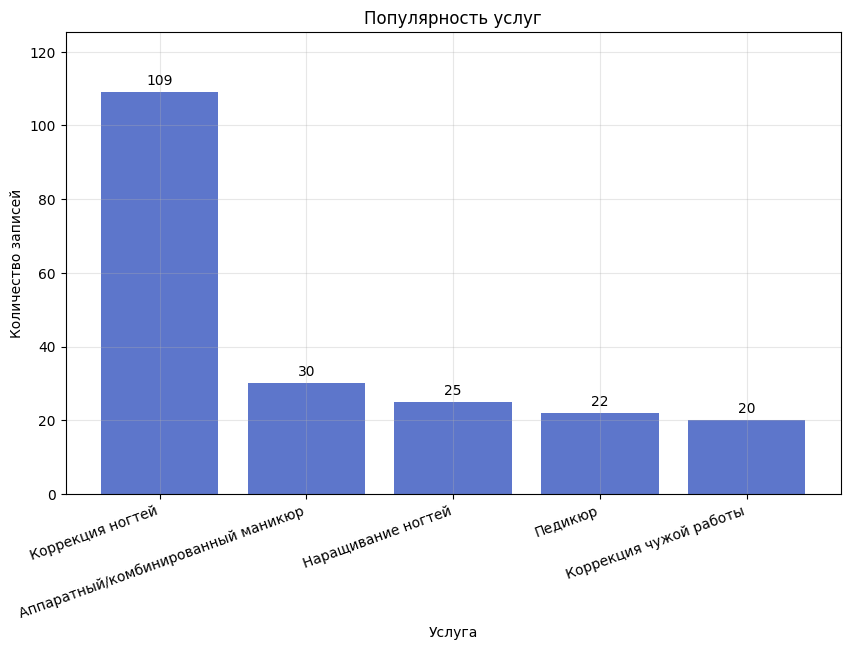

In [3]:
completed_appointments = df[df["status"] == "Завершено"]
counts = completed_appointments["service"].value_counts()

plt.figure(figsize=(10, 6))
plt.bar(counts.index, counts, color="#5d76cb")
plt.title("Популярность услуг")
plt.xlabel("Услуга")
plt.ylabel("Количество записей")
plt.ylim(0, counts.max() * 1.15)
plt.xticks(rotation=20, ha="right")
plt.grid(alpha=0.3)
for i in range(len(counts)):
    label = counts.index[i]
    value = counts.iloc[i]
    plt.text(label, value + 2, f"{value}", ha="center")
plt.show()

По завершённым записям самой популярной услугой является "Коррекция ногтей" — 109 записей. Она заметно опережает остальные услуги. Самая непопулярная услуга — "Коррекция чужой работы" (20 записей). Таким образом, "Коррекция ногтей" составляет основу спроса и формирует большую часть потока записей, тогда как остальные процедуры востребованы заметно реже.

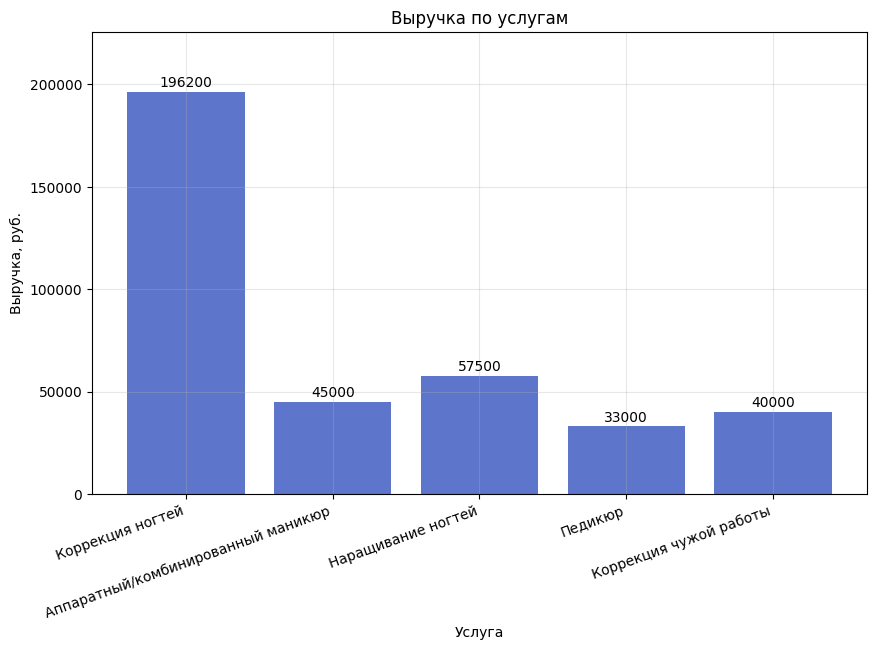

In [4]:
prices = completed_appointments.groupby("service")["price"].sum()
prices = prices.reindex(counts.index)

plt.figure(figsize=(10, 6))
plt.bar(prices.index, prices, color="#5d76cb")
plt.title("Выручка по услугам")
plt.xlabel("Услуга")
plt.ylabel("Выручка, руб.")
plt.ylim(0, prices.max() * 1.15)
plt.xticks(rotation=20, ha="right")
plt.grid(alpha=0.3)
for i in range(len(prices)):
    label = prices.index[i]
    value = prices.iloc[i]
    plt.text(label, value + 2500, f"{value}", ha="center")
plt.show()

По завершённым записям наибольшую выручку приносит услуга «Коррекция ногтей» — 196 200 руб. Она заметно опережает выручку остальных услуг. Наименьшую выручку приносит «Педикюр» — 33 000 руб. При этом «Наращивание ногтей» приносит большую выручку (57 500 руб.), чем «Аппаратный/комбинированный маникюр» (45 000 руб.), несмотря на меньшую популярность. Таким образом, «Коррекция ногтей» является главным источником дохода. Остальные услуги приносят меньшую выручку.

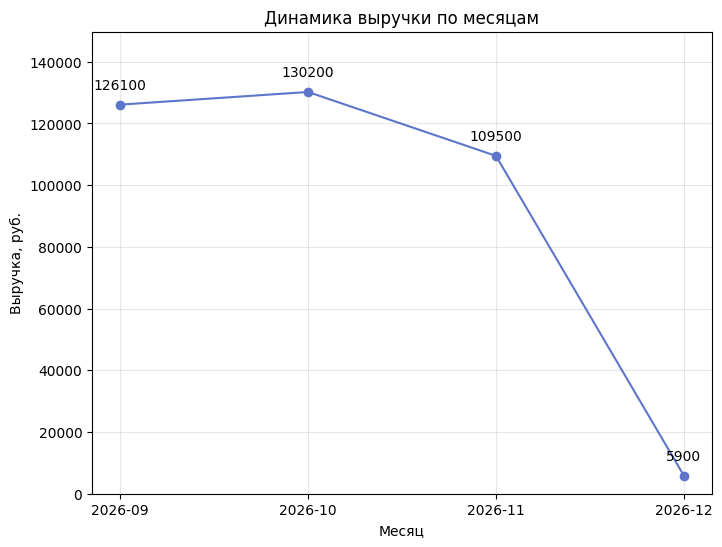

In [5]:
months = completed_appointments["date"].dt.to_period("M")
monthly_income = completed_appointments.groupby(months)["price"].sum()

plt.figure(figsize=(8, 6))
plt.plot(monthly_income.index.astype(str), monthly_income, marker='o', color="#5d76cb")
plt.title("Динамика выручки по месяцам")
plt.xlabel("Месяц")
plt.ylabel("Выручка, руб.")
plt.ylim(0, monthly_income.max() * 1.15)
plt.grid(alpha=0.3)
for i in range(len(monthly_income)):
    label = monthly_income.index.astype(str)[i]
    value = monthly_income.iloc[i]
    plt.text(label, value + 5000, f"{value}", ha="center")
plt.show()

По завершённым записям наибольшая выручка зафиксирована в октябре 2026 года — 130 200 руб. В целом с сентября по ноябрь выручка держится на стабильном уровне (от 109 500 до 130 200 руб.). Резкое снижение в декабре до 5 900 руб. связано с тем, что месяц ещё не закончился и часть записей остаётся в статусе «Запланировано». Таким образом, в завершённых периодах доход остаётся стабильным без резких перепадов.

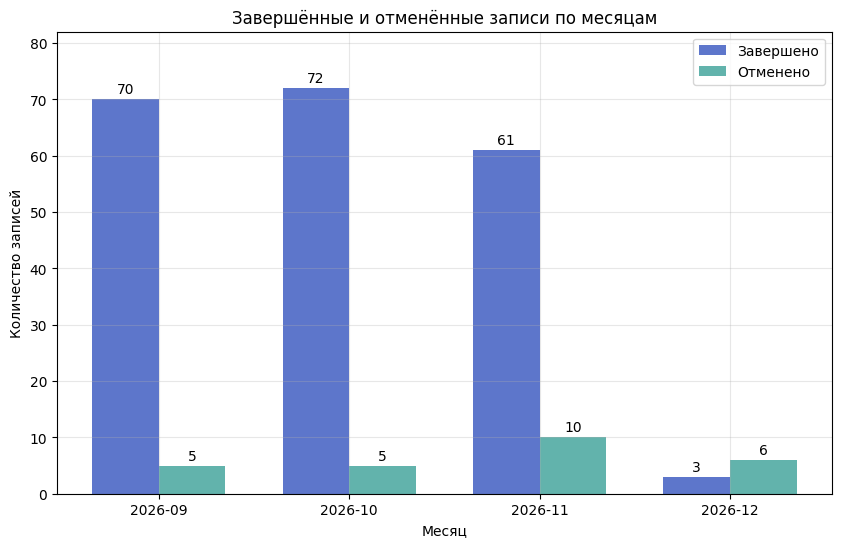

In [6]:
completed = df[df["status"] == "Завершено"]
canceled = df[df["status"] == "Отменено"]
completed_by_month = completed.groupby(completed["date"].dt.to_period("M")).size()
canceled_by_month = canceled.groupby(canceled["date"].dt.to_period("M")).size()
canceled_by_month = canceled_by_month.reindex(completed_by_month.index, fill_value=0)

months_labels = completed_by_month.index.astype(str)
x = np.arange(len(months_labels))
width = 0.35

plt.figure(figsize=(10, 6))
bars_completed = plt.bar(x - width / 2, completed_by_month, width, label="Завершено", color="#5d76cb")
bars_canceled = plt.bar(x + width / 2, canceled_by_month, width, label="Отменено", color="#62b3ac")
plt.title("Завершённые и отменённые записи по месяцам")
plt.xlabel("Месяц")
plt.ylabel("Количество записей")
plt.xticks(x, months_labels)
plt.ylim(0, max(completed_by_month.max(), canceled_by_month.max()) + 10)
plt.legend()
plt.grid(alpha=0.3)

for i in range(len(months_labels)):
    completed_val = completed_by_month.iloc[i]
    canceled_val = canceled_by_month.iloc[i]
    plt.text(x[i] - width / 2, completed_val + 1, f"{completed_val}", ha="center")
    plt.text(x[i] + width / 2, canceled_val + 1, f"{canceled_val}", ha="center")

plt.show()

Наибольшее количество завершённых записей зафиксировано в октябре 2026 года — 72. В целом с сентября по ноябрь завершённые записи держатся на стабильном уровне (от 61 до 72). При этом наибольшее количество отмен зафиксировано в ноябре 2026 года — 10. Низкие показатели в декабре связаны с тем, что месяц ещё не закончился и часть записей остаётся в статусе «Запланировано». Таким образом, в завершённых периодах большинство записей успешно завершается, а число отмен остаётся невысоким без резких перепадов.